# Feature engineering theo giả thuyết nghiệp vụ

**Câu hỏi:** ngoài 18 feature lịch sử hiện có, thông tin về chu kỳ mua, thay đổi hoạt động, thành phần basket, discount và kích thước chuyến mua có cải thiện xác suất và xếp hạng không?

Mỗi thí nghiệm chỉ thêm **một nhóm** vào cùng 18 feature. Logistic Regression và LightGBM dùng cùng cấu hình với vòng trước; không tuning, không đọc test. Validation được dùng lựa chọn feature nên các kết quả dưới đây chỉ là thăm dò, chưa phải xác nhận độc lập. Mọi phép tính dùng thông tin đến cutoff.

## 1. Dữ liệu và nguyên tắc point-in-time

Nạp train và validation theo hợp đồng; chỉ đọc dữ liệu giao dịch tới cutoff validation cuối. Một basket dùng `(household_key, BASKET_ID, DAY)`; các cửa sổ là `(cutoff - w, cutoff]`. Chưa sử dụng demographic, campaign hay `QUANTITY`. Giá trị thiếu thể hiện không đủ quan sát, không mặc định là 0.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
ROOT=Path.cwd()
if ROOT.name == 'research' and ROOT.parent.name == 'notebooks': ROOT = ROOT.parent
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
if (ROOT/'.deps').is_dir():sys.path.insert(0,str(ROOT/'.deps'))
from propensity_v2.prepared_data import load_prepared_split
from lightgbm import LGBMClassifier
DATA=ROOT/'artifacts'/'data_preparation'; OUT=ROOT/'artifacts'/'research'/'feature_experiments'
train,features=load_prepared_split(DATA,'train');val,vfeatures=load_prepared_split(DATA,'validation')
assert features==vfeatures and train.snapshot_day.max()+7<val.snapshot_day.min()
base=pd.concat([train,val],ignore_index=True)
assert not base.duplicated(['household_key','snapshot_day']).any()
tx=pd.read_csv(ROOT/'sample_data'/'dunnhumby'/'transaction_data.csv',
               usecols=['household_key','BASKET_ID','DAY','PRODUCT_ID','RETAIL_DISC','COUPON_DISC','COUPON_MATCH_DISC'])
tx=tx.loc[tx.DAY<=val.snapshot_day.max()].copy()
products=pd.read_csv(ROOT/'sample_data'/'dunnhumby'/'product.csv',usecols=['PRODUCT_ID','DEPARTMENT'])
assert products.PRODUCT_ID.is_unique
tx=tx.merge(products,on='PRODUCT_ID',how='left',validate='many_to_one')
assert tx.DEPARTMENT.notna().all()
tx['has_discount']=tx.RETAIL_DISC.lt(0)|tx.COUPON_DISC.lt(0)|tx.COUPON_MATCH_DISC.lt(0)
tx['is_fuel']=tx.DEPARTMENT.eq('KIOSK-GAS')
baskets=(tx.groupby(['household_key','BASKET_ID','DAY'],as_index=False,sort=False)
         .agg(lines=('PRODUCT_ID','size'),discount=('has_discount','max'),fuel=('is_fuel','max'),fuel_only=('is_fuel','min')))
active=baskets[['household_key','DAY']].drop_duplicates().sort_values(['household_key','DAY'])
departments=tx[['household_key','DAY','DEPARTMENT']].drop_duplicates()
print('Train:',len(train),'| Validation:',len(val),'| Cutoff cuối:',val.snapshot_day.max())

Train: 129834 | Validation: 27480 | Cutoff cuối: 621


## 2. Tạo feature theo từng giả thuyết

- **Cadence:** trung vị và độ lệch chuẩn của khoảng cách giữa các ngày mua trong 180 ngày; tỷ lệ recency/trung vị. Chỉ có một khoảng cách thì độ lệch chuẩn chưa xác định; cờ cho biết có đủ khoảng cách.
- **Thay đổi hoạt động:** so sánh 30 ngày gần nhất với 30 ngày trước đó, đếm ngày hoạt động và basket.
- **Giỏ hàng:** số department trong 90 ngày; tỷ lệ basket có fuel và chỉ fuel.
- **Discount:** tỷ lệ basket có ít nhất một discount âm trong 30/90 ngày, và thay đổi giữa hai giai đoạn 30 ngày.
- **Chuyến mua:** trung vị số dòng và tỷ lệ basket một dòng trong 90 ngày.

Các tỷ lệ không xác định khi mẫu số bằng 0. Imputer của Logistic chỉ học median trên train; LightGBM nhận giá trị thiếu trực tiếp. Không dùng `QUANTITY` để cộng lượng hàng.

In [2]:
groups={
 'Chu kỳ mua':['cadence_median_gap_180d','cadence_gap_std_180d','cadence_recency_ratio','cadence_has_gap','cadence_has_two_gaps'],
 'Thay đổi hoạt động':['trend_active_diff_30d','trend_baskets_diff_30d'],
 'Thành phần basket':['department_count_90d','fuel_basket_share_90d','fuel_only_share_90d'],
 'Discount':['discount_share_30d','discount_share_90d','discount_share_change_30d'],
 'Chuyến mua':['basket_lines_median_90d','single_line_share_90d']}
feature_names=sum(groups.values(),[])
assert not set(feature_names)&set(features)
records=[]
for s in sorted(base.snapshot_day.unique()):
    eligible=base.loc[base.snapshot_day.eq(s),['household_key','snapshot_day','recency_days']].copy().set_index('household_key')
    a=active.loc[active.DAY.between(s-179,s)].copy()
    a['gap']=a.groupby('household_key').DAY.diff()
    gaps=a.groupby('household_key').gap.agg(['count','median','std'])
    eligible['cadence_median_gap_180d']=gaps['median']
    eligible['cadence_gap_std_180d']=gaps['std']
    eligible['cadence_has_gap']=gaps['count'].ge(1).reindex(eligible.index,fill_value=False).astype(int)
    eligible['cadence_has_two_gaps']=gaps['count'].ge(2).reindex(eligible.index,fill_value=False).astype(int)
    eligible['cadence_recency_ratio']=eligible.recency_days/eligible.cadence_median_gap_180d
    b=baskets.loc[baskets.DAY.between(s-89,s)].copy()
    b30=b.loc[b.DAY>s-30]; prev=b.loc[(b.DAY>s-60)&(b.DAY<=s-30)]
    recent_stats=b30.groupby('household_key').agg(recent_baskets=('BASKET_ID','size'),recent_days=('DAY','nunique'),recent_discount=('discount','mean'))
    previous_stats=prev.groupby('household_key').agg(previous_baskets=('BASKET_ID','size'),previous_days=('DAY','nunique'),previous_discount=('discount','mean'))
    eligible=eligible.join(recent_stats).join(previous_stats)
    eligible['trend_active_diff_30d']=eligible.recent_days.fillna(0)-eligible.previous_days.fillna(0)
    eligible['trend_baskets_diff_30d']=eligible.recent_baskets.fillna(0)-eligible.previous_baskets.fillna(0)
    d=departments.loc[departments.DAY.between(s-89,s)].groupby('household_key').DEPARTMENT.nunique()
    eligible['department_count_90d']=d.reindex(eligible.index).fillna(0)
    stats=b.groupby('household_key').agg(fuel_basket_share_90d=('fuel','mean'),fuel_only_share_90d=('fuel_only','mean'),
                                       discount_share_90d=('discount','mean'),basket_lines_median_90d=('lines','median'),
                                       single_line_share_90d=('lines',lambda x:x.eq(1).mean()))
    eligible=eligible.join(stats)
    eligible['discount_share_30d']=eligible.recent_discount
    eligible['discount_share_change_30d']=eligible.recent_discount-eligible.previous_discount
    records.append(eligible.reset_index()[['household_key','snapshot_day']+feature_names])
new=pd.concat(records,ignore_index=True)
assert not new.duplicated(['household_key','snapshot_day']).any()
table=base.merge(new,on=['household_key','snapshot_day'],validate='one_to_one',how='left')
assert len(table)==len(base) and not table[feature_names].isin([np.inf,-np.inf]).any().any()
print('Household-snapshot:',len(table),'| Feature mới:',len(feature_names))
display(table.loc[table.split.eq('train'),feature_names].isna().mean().rename('tỷ lệ thiếu train').to_frame())

Household-snapshot: 157314 | Feature mới: 15


,tỷ lệ thiếu train
cadence_median_gap_180d,0.063535
cadence_gap_std_180d,0.095276
cadence_recency_ratio,0.063535
cadence_has_gap,0.000000
cadence_has_two_gaps,0.000000
trend_active_diff_30d,0.000000
trend_baskets_diff_30d,0.000000
department_count_90d,0.000000
fuel_basket_share_90d,0.079771
fuel_only_share_90d,0.079771


## 3. Kiểm tra một mẫu trực tiếp từ basket nguồn

Đối chiếu độc lập 200 household–snapshot train: khoảng cách, số ngày hoạt động, số department, tỷ lệ discount và kích thước basket. Kiểm tra này cùng các cửa sổ rõ ràng giúp phát hiện sai lệch triển khai; không chứng minh nguồn hoàn chỉnh.

In [3]:
sample=table.loc[table.split.eq('train')].sample(200,random_state=42)
b_by={h:g for h,g in baskets.groupby('household_key',sort=False)}
d_by={h:g for h,g in departments.groupby('household_key',sort=False)}
for row in sample.itertuples(index=False):
    b=b_by[row.household_key]; s=row.snapshot_day
    b90=b[(b.DAY>s-90)&(b.DAY<=s)]; b180=b[(b.DAY>s-180)&(b.DAY<=s)]
    day_gaps=np.diff(np.sort(b180.DAY.unique()))
    assert row.cadence_has_gap==int(len(day_gaps)>=1)
    if len(day_gaps): assert np.isclose(row.cadence_median_gap_180d,np.median(day_gaps))
    else: assert pd.isna(row.cadence_median_gap_180d)
    recent=b[(b.DAY>s-30)&(b.DAY<=s)];previous=b[(b.DAY>s-60)&(b.DAY<=s-30)]
    assert row.trend_active_diff_30d==recent.DAY.nunique()-previous.DAY.nunique()
    assert row.trend_baskets_diff_30d==len(recent)-len(previous)
    d=d_by[row.household_key]; assert row.department_count_90d==d.loc[(d.DAY>s-90)&(d.DAY<=s),'DEPARTMENT'].nunique()
    if len(b90):
        assert np.isclose(row.discount_share_90d,b90.discount.mean())
        assert np.isclose(row.fuel_only_share_90d,b90.fuel_only.mean())
        assert np.isclose(row.basket_lines_median_90d,b90.lines.median())
print('PASS: đối chiếu 200 household–snapshot train với basket và department nguồn.')

PASS: đối chiếu 200 household–snapshot train với basket và department nguồn.


## 4. Thử nghiệm từng nhóm feature

Mỗi model được fit trên train; validation chỉ dùng đánh giá. Brier/log loss càng thấp càng tốt; ROC-AUC và lift càng cao càng tốt. Lift được tính top 10% theo từng cutoff, lấy kỳ vọng khi đồng điểm rồi tính trung bình 11 cutoff. Thử nhiều nhóm trên cùng validation có thể tạo cải thiện ngẫu nhiên; không xem kết quả như test độc lập.

In [4]:
def weekly_lift(frame,p):
    values=[]
    for ix in frame.groupby('snapshot_day').indices.values():
        y=frame.target_any_basket.to_numpy()[ix]; q=p[ix]; k=int(np.ceil(.1*len(y)))
        threshold=np.partition(q,len(q)-k)[len(q)-k]; higher=q>threshold; tied=q==threshold
        precision=(y[higher].sum()+(k-higher.sum())*y[tied].mean())/k
        values.append(precision/y.mean() if y.mean() else np.nan)
    return np.array(values)

tr=table.loc[table.split.eq('train')].reset_index(drop=True)
va=table.loc[table.split.eq('validation')].reset_index(drop=True)
experiments={'A: 18 feature':[]}|groups
rows=[];weekly=[]
for experiment,extra in experiments.items():
    cols=features+extra
    for name in ['Logistic Regression','LightGBM']:
        if name=='Logistic Regression':
            model=make_pipeline(SimpleImputer(strategy='median',keep_empty_features=True),StandardScaler(),LogisticRegression(max_iter=2000,random_state=42))
        else:
            model=LGBMClassifier(n_estimators=200,learning_rate=.05,num_leaves=15,min_child_samples=100,random_state=42,verbosity=-1,n_jobs=2)
        model.fit(tr[cols],tr.target_any_basket)
        prob=model.predict_proba(va[cols])[:,1]
        assert np.isfinite(prob).all() and ((prob>=0)&(prob<=1)).all()
        lifts=weekly_lift(va,prob)
        rows.append({'experiment':experiment,'model':name,'features':len(cols),'brier':brier_score_loss(va.target_any_basket,prob),
                     'log_loss':log_loss(va.target_any_basket,prob,labels=[0,1]),'roc_auc':roc_auc_score(va.target_any_basket,prob),
                     'weekly_lift_mean':lifts.mean()})
        for cutoff,lift in zip(sorted(va.snapshot_day.unique()),lifts):weekly.append({'experiment':experiment,'model':name,'snapshot_day':cutoff,'lift':lift})
results=pd.DataFrame(rows);weekly=pd.DataFrame(weekly)
base_result=results.loc[results.experiment.eq('A: 18 feature')].set_index('model')
for metric in ['brier','log_loss','roc_auc','weekly_lift_mean']:
    results['delta_'+metric]=results[metric]-results.model.map(base_result[metric])
display(results.sort_values(['model','brier']))

,experiment,model,features,brier,log_loss,roc_auc,weekly_lift_mean,delta_brier,delta_log_loss,delta_roc_auc,delta_weekly_lift_mean
3,Chu kỳ mua,LightGBM,23,0.164026,0.494306,0.837327,1.791297,-3.622397e-04,-0.001099,0.000665,0.004715
11,Chuyến mua,LightGBM,20,0.164286,0.495125,0.836845,1.785915,-1.026433e-04,-0.000280,0.000183,-0.000666
9,Discount,LightGBM,21,0.164370,0.495306,0.836703,1.784541,-1.822756e-05,-0.000099,0.000041,-0.002040
1,A: 18 feature,LightGBM,18,0.164389,0.495405,0.836662,1.786582,0.000000e+00,0.000000,0.000000,0.000000
7,Thành phần basket,LightGBM,21,0.164389,0.495416,0.836648,1.784536,1.201700e-08,0.000011,-0.000013,-0.002045
5,Thay đổi hoạt động,LightGBM,20,0.164398,0.495454,0.836648,1.787926,9.515248e-06,0.000049,-0.000014,0.001344
2,Chu kỳ mua,Logistic Regression,23,0.165541,0.499085,0.834424,1.779747,-8.299908e-04,-0.002586,0.001408,0.002004
4,Thay đổi hoạt động,Logistic Regression,20,0.166226,0.501355,0.833336,1.779743,-1.453126e-04,-0.000316,0.000319,0.002000
10,Chuyến mua,Logistic Regression,20,0.166359,0.501624,0.833043,1.775731,-1.276292e-05,-0.000047,0.000027,-0.002013
0,A: 18 feature,Logistic Regression,18,0.166371,0.501671,0.833017,1.777743,0.000000e+00,0.000000,0.000000,0.000000


## 5. Tính ổn định theo cutoff

Chênh lệch lift được so sánh với cùng mô hình và cùng cutoff ở thí nghiệm A. Số tuần tăng không phải kiểm định ý nghĩa thống kê; các household lặp lại theo thời gian. Chỉ số xác suất toàn validation và lift tuần cần được đọc đồng thời.

,model,experiment,mean_delta_lift,min_delta_lift,max_delta_lift,weeks_improved,weeks
1,LightGBM,Chu kỳ mua,0.004715,-0.015054,0.029497,6,11
4,LightGBM,Thay đổi hoạt động,0.001344,-0.007527,0.014576,4,11
0,LightGBM,A: 18 feature,0.000000,0.000000,0.000000,0,11
2,LightGBM,Chuyến mua,-0.000666,-0.007728,0.014748,3,11
3,LightGBM,Discount,-0.002040,-0.014576,0.014748,2,11
5,LightGBM,Thành phần basket,-0.002045,-0.014902,0.014748,3,11
7,Logistic Regression,Chu kỳ mua,0.002004,-0.007418,0.007451,4,11
10,Logistic Regression,Thay đổi hoạt động,0.002000,-0.007347,0.007541,4,11
11,Logistic Regression,Thành phần basket,0.000718,-0.007347,0.007728,3,11
6,Logistic Regression,A: 18 feature,0.000000,0.000000,0.000000,0,11


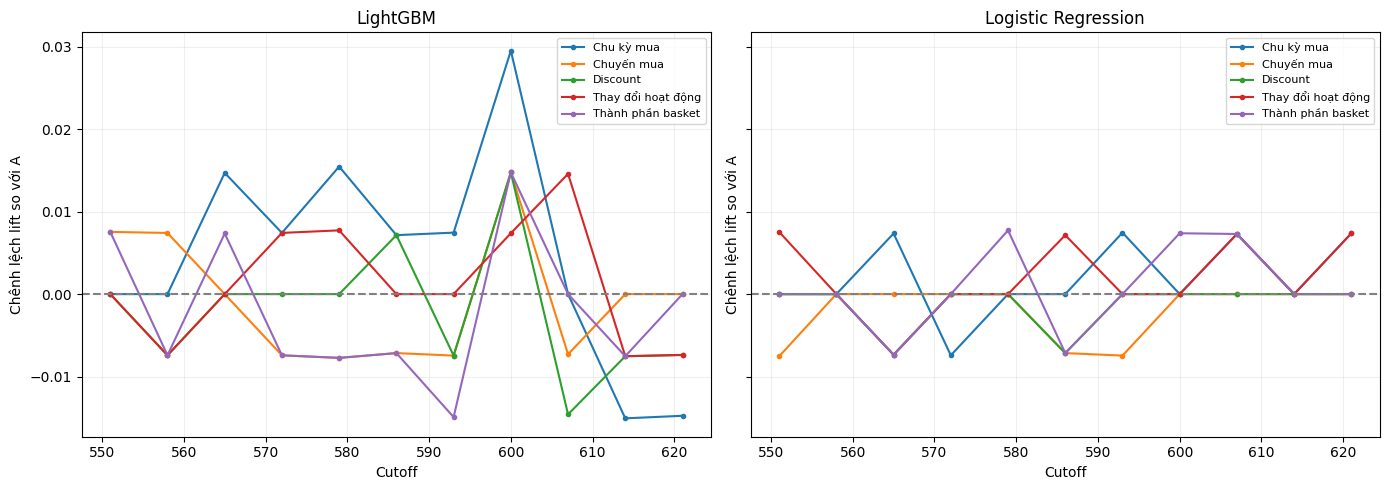

In [5]:
reference=weekly.loc[weekly.experiment.eq('A: 18 feature'),['model','snapshot_day','lift']].rename(columns={'lift':'baseline_lift'})
weekly=weekly.merge(reference,on=['model','snapshot_day'],validate='many_to_one')
weekly['delta_lift']=weekly.lift-weekly.baseline_lift
stability=(weekly.groupby(['model','experiment'],as_index=False)
           .agg(mean_delta_lift=('delta_lift','mean'),min_delta_lift=('delta_lift','min'),
                max_delta_lift=('delta_lift','max'),weeks_improved=('delta_lift',lambda x:int((x>1e-10).sum())),weeks=('delta_lift','size')))
display(stability.sort_values(['model','mean_delta_lift'],ascending=[True,False]))
fig,axes=plt.subplots(1,2,figsize=(14,5),sharey=True)
for ax,(name,g) in zip(axes,weekly.groupby('model')):
    for exp,v in g.groupby('experiment'):
        if exp!='A: 18 feature':ax.plot(v.snapshot_day,v.delta_lift,marker='.',label=exp)
    ax.axhline(0,color='gray',linestyle='--');ax.set(title=name,xlabel='Cutoff',ylabel='Chênh lệch lift so với A');ax.grid(alpha=.2);ax.legend(fontsize=8)
plt.tight_layout();plt.show()

**Nhận xét sau thử nghiệm:** Nhóm chu kỳ mua cải thiện Brier trên cả hai mô hình và lift trung bình tăng nhẹ; với LightGBM lift tăng ở 6/11 cutoff, giảm hoặc không tăng ở các cutoff còn lại. Các nhóm khác chưa cho cải thiện nhất quán trên tất cả các chỉ số. Đây là kết quả chọn lọc trên validation, không khẳng định feature sẽ cải thiện ở dữ liệu tương lai. Việc nối department dùng catalog hiện có; tính sẵn có và ổn định lịch sử của mô tả sản phẩm chưa được xác minh đầy đủ.


## 6. Lưu kết quả và giới hạn

Các nhóm chưa được kết hợp và chưa điều chỉnh tham số. Không quyết định dựa vào một chênh lệch nhỏ duy nhất; cần kiểm tra chi phí tạo feature, độ bền theo thời gian và xác suất. Dữ liệu test từng được xem; cần dữ liệu tương lai chưa tham gia lựa chọn cho xác nhận độc lập. Tác động can thiệp marketing không được đo ở đây.

In [6]:
OUT.mkdir(parents=True,exist_ok=True)
results.to_csv(OUT/'validation_feature_ablation.csv',index=False,encoding='utf-8-sig')
weekly.to_csv(OUT/'validation_weekly_lift.csv',index=False,encoding='utf-8-sig')
stability.to_csv(OUT/'validation_lift_stability.csv',index=False,encoding='utf-8-sig')
print('Đã lưu:',OUT)

Đã lưu: artifacts\feature_experiments
